In [ ]:
#| echo: false

import os
from time import time
import scipy.stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, \
                                          QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.svm import LinearSVC, SVC

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, \
                             AdaBoostClassifier, GradientBoostingClassifier

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV, train_test_split, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=598)

In [ ]:
#| echo: false

NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))
df_raw = pd.read_csv(os.path.join(NOTEBOOK_DIR, "source_data", "kepler_koi.csv"))

In [ ]:
#| echo: false

X = df_raw.drop(columns=["kepoi_name", "koi_disposition"])
Y = df_raw["koi_disposition"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                    test_size=0.3,
                                                    random_state=598,
                                                    stratify=Y)

In [ ]:
#| echo: false

# keep only rows with 5 or fewer missing values
keep_mask_train = X_train.isna().sum(axis=1) <= 5
X_train = X_train.loc[keep_mask_train].copy()
Y_train = Y_train.loc[keep_mask_train].copy()

keep_mask_test = X_test.isna().sum(axis=1) <= 5
X_test = X_test.loc[keep_mask_test].copy()
Y_test = Y_test.loc[keep_mask_test].copy()

In [ ]:
#| echo: false

# for any missing values now, use the median of that feature's distribution 
# using training-data distribution only
feature_cols = X_train.columns
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[feature_cols])
X_train = pd.DataFrame(imputer.transform(X_train[feature_cols]), columns=feature_cols, index=X_train.index)
X_test  = pd.DataFrame(imputer.transform(X_test[feature_cols]),  columns=feature_cols, index=X_test.index)

# INTRO
This project focuses on the task of analyzing data from "objects of interest" orbiting stars to infer whether the object is a planet or not. Specifically, can transit geometry and host-star characteristics documented in the [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu) cumulative KOI table distinguish the confirmed planets from false positives? Which classifier performs best on this task, and which have the best characteristics supporting further analysis?  
I used Python to explore the dataset and develop models to answer these questions.

## Data Ingestion

The dataset has the following columns:  

### Transit/Planet Features

| Feature | Description |
|---|---|
| `koi_period` | Orbital Period [days] |
| `koi_duration` | Transit Duration [hours] |
| `koi_depth` | Transit Depth [ppm] |
| `koi_impact` | Impact Parameter |
| `koi_model_snr` | Transit Signal-to-Noise |
| `koi_prad` | Planetary Radius [Earth radii] |
| `koi_teq` | Equilibrium Temperature [K] |
| `koi_insol` | Insolation Flux (Earth flux) |
| `koi_sma` | Orbit Semi-Major Axis (au) |
| `koi_incl` | Inclination [deg] |
| `koi_ror` | Planet-to-Star Radius Ratio |
		
### Host-star Features

| Feature | Description |
|---|---|
| `koi_steff` | Stellar Effective Temperature [K] |
| `koi_slogg` | Stellar Surface Gravity (log10 cm s^-2) |
| `koi_srad` | Stellar Radius [Solar radii] |
| `koi_smass` | Stellar Mass [Solar masses] |
| `koi_smet` | Stellar metallicity [dex] |
| `koi_kepmag` | Kepler-band [mag] |
| `koi_srho` | Fitted Stellar Density [g cm^-3] |

Finally, there is an ID column and a "disposition" that will act as the response variable.  
Only entries labeled with a "confirmed" or "false positive" disposition are to be used for the classifier task. The Exoplanet archive includes "candidate" entries, but those were excluded from this analysis. The class frequencies are uneven (~36% confirmed vs. ~64% false positive).  
The dataset contains 7587 entries (one per object of interest).  

## Test/train split

I split the dataset into a training set (70%) and a held-out test/validation set (30%) that was not used for tuning, cross-validation, etc. I made sure the test/train split was stratified by the response variables (`koi_disposition`) due to class imbalance.  

## Missing values
Around 3.5-4% of the objects/rows had missing values. Many of these rows were missing the *majority* of their values. I decided to exclude records missing more than 5 values; recovery of those training samples via imputation would yield almost entirely-artificial "observations".  
After imposing that missingness threshold, the remaining records had at most 1 missing value, in these fields:

| Feature | Description |  
|---|---| 
| `koi_smet` | Stellar metallicity | 
| `koi_kepmag` | Kepler-band magnitude | 
| `koi_incl` | Inclination | 

I used median imputation for these missing values (13 rows in training set and 9 in test set).   
Each of the features distributions appeared unimodal and well-behaved, so I judged the median would be a safe substitute.  

## Feature scaling
The scale of the features spanned orders of magnitude, which can cause issues with some algorithms, especially those using distance calculations. For all models except the random forest, I scaled the features (based on training data only) before fitting the model.  

SVM requires scaling since the distance calculations and weight penalties can be skewed by larger differences in feature magnitude. RBF-kernel SVM especially needs scaling since it uses a dot product, which can also be skewed by mismatched feature scales.  
Standard logistic regression and LDA did not require it in general, but it is computationally cheap, and large differences in feature scale can cause numerical instability in some cases. I also planned to try regularized logistic regression later, which requires feature scaling due to penalizing feature-scale-dependent parameter values. For these reasons,  I included scaling in the pipelines for all these methods from the start.  
The tree-based methods do not benefit from it at all, so I omitted scaling from those models' preprocessing.  


## Classification
I visualized the pair plot of all predictors and saw significant overlap (almost indistinguishable) in all plots. There is no obvious separation using any pair of variables by themselves. I was interested to see how a classifier would perform in the higher-dimensional space.  
In many cases, the equal-covariance assumption is obviously false, so I knew LDA would not be my preferred method, even if it happened to give good results.  

All cross-validation was performed on the training set with the same 5-fold split using seed 598, initialized up front.  
All randomized algorithms were also initialized with random seed 598 (e.g., randomized searches for hyperparameters, logistic regression, random forest ensemble).  

Cases where the classifier incorrectly labels an object as a confirmed planet will be treated as a false positive. An erroneous rejection of an object will be a false negative.  

### LDA

[]  

| Accuracy Metric | Value |
|---|---|
| `Training` | 0.83177 |
| `CV-avg Training` | 0.83001 |
| `Test` | 0.82441 |


In [ ]:
#| echo: false

lda_model = LinearDiscriminantAnalysis()
lda_model = make_pipeline(
                        StandardScaler(),
                        LinearDiscriminantAnalysis())
lda_model.fit(X_train, Y_train);

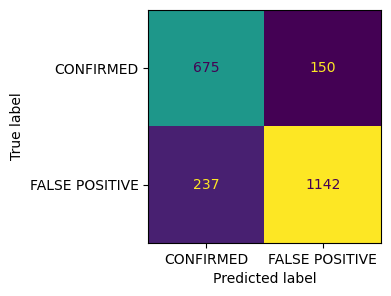

In [19]:
#| echo: false

with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_test, lda_model.predict(X_test),
      labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
      colorbar=False
   )
   plt.gcf().set_size_inches(4, 4)
   plt.tight_layout();

The LDA classifier produced a 17.2% false-positive rate and 18.2% false-negative rate on the test data.



### Logistic regression

[]

| Accuracy Metric | Value |
|---|---|
| `Training accuracy` | 0.863387 |
| `Cross-validated average training accuracy` | 0.86085 |
| `Test accuracy` | 0.863430 |


In [22]:
#| echo: false
# logreg_model = LogisticRegression(random_state=598) # convergence problem
logreg_model = make_pipeline(
                        StandardScaler(),
                        LogisticRegression(random_state=598))
logreg_model.fit(X_train, Y_train);

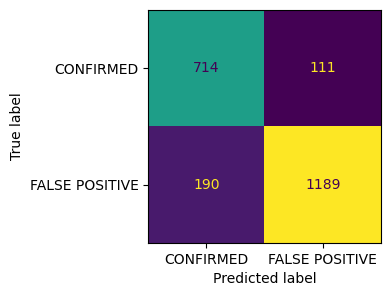

In [23]:
#| echo: false
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_test, logreg_model.predict(X_test),
      labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
      colorbar=False,
   )
   plt.gcf().set_size_inches(4, 4)
   plt.tight_layout();

The logistic-regression classifier produced a 13.8% false-positive rate and 13.5% false-negative rate on the test data.


### Linear SVM
When fitting the linear SVM, I had to solve the primal form because the dual was failing to converge.  
I used L2 norm as the penalty.  
In searching for the C hyperparameter, I used randomized search of a log-uniform(1,100) distribution, with 40 iterations, scored with cross validation (training data only). The best C found was ~10.4.  

| Accuracy Metric | Value |
|---|---|
| `Training accuracy` | 0.86963 |
| `Cross-validated average training accuracy` | 0.86807 |
| `Test accuracy` | 0.87386 |

In [29]:
#| echo: false
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html#sklearn.svm.LinearSVC
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html#sklearn.linear_model.SGDClassifier
# For best results using the default learning rate schedule, the data should have zero mean and unit variance.

svm_linear = make_pipeline(StandardScaler(),
                           LinearSVC(penalty="l2",
                                     dual=False,           # had to set this false to achieve convergence
                                     random_state=598))
svm_linear.fit(X_train, Y_train);

In [46]:
#| echo: false
C_grid = {'linearsvc__C': scipy.stats.loguniform(1, 100)}

svm_linear_C_search = RandomizedSearchCV(
    estimator=svm_linear,
    param_distributions=C_grid,
    n_iter=40,
    random_state=598,
    n_jobs=2,
    cv=kf
)

svm_linear_C_search.fit(X_train, Y_train)
svm_linear_C_optimized = svm_linear_C_search.best_estimator_;

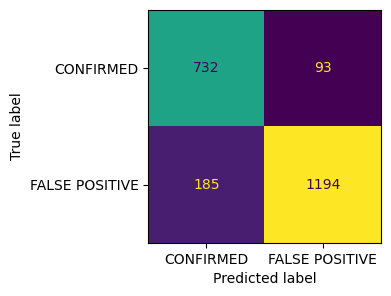

In [31]:
#| echo: false
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_test, svm_linear_C_optimized.predict(X_test),
      labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
      colorbar=False
   )
   plt.gcf().set_size_inches(4, 4)
   plt.tight_layout();

The linear SVM classifier produced a 13.4% false-positive rate and an 11.3% false-negative rate on the test data.  

Compared to logistic regression, SVM disagrees on 180 out of 2204 test samples (~8%). Logistic regression appears more biased to classify confirmed planets as false positives (putting them in majority class).  


[cross-tab]


SVM's decision function is a learned boundary/hyperplane through the 18-dimensional feature space, trying to carve the best separateion between the two classes. Its hinge loss function is not influenced by the points outside the margin, because their hinge loss is zero. It is only influenced by those within the margin next to the hyperplane (with margin width determined by hyperparameter C). Logistic regression applies logistic loss to all samples based on assigned probabilities, therefore it can be biased to predict for the majority class when the classes are imbalanced; they have more loss contributors.  


### Kernel SVM (RBF kernel)
The kernel I chose for nonlinear SVM was the RBF kernel (radial basis function).  
I again used randomized search, this time in two dimensions. The algorithm drew C values from a log-uniform(1,100) distribution, and values of gamma from loguniform(1e-4, 1). Forty iterations were run an scored with cross validation (training data only).  
The optimal cost parameter C found was 36.7, and the optimal gamma parameter found was 0.058.  


| Accuracy Metric | Value |
|---|---|
| `Training accuracy` | 0.911397 |
| `Cross-validated average training accuracy` | 0.89422 |
| `Test accuracy` | 0.8892921 |


In [35]:
#| echo: false
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html#sklearn.linear_model.SGDClassifier
# For best results using the default learning rate schedule, the data should have zero mean and unit variance.

svm_rbf = make_pipeline(StandardScaler(),
                        SVC(kernel="rbf",
                            random_state=598))
svm_rbf.fit(X_train, Y_train);

In [ ]:
#| echo: false
C_and_gamma_grid = {'svc__C': scipy.stats.loguniform(1, 100),
                    'svc__gamma': scipy.stats.loguniform(1e-4, 1)
                    }

svm_rbf_C_search = RandomizedSearchCV(
    estimator=svm_rbf,
    param_distributions=C_and_gamma_grid,
    n_iter=40,
    random_state=598,
    n_jobs=2,
    cv=kf
)
svm_rbf_C_search.fit(X_train, Y_train)
svm_rbf_C_optimized = svm_rbf_C_search.best_estimator_

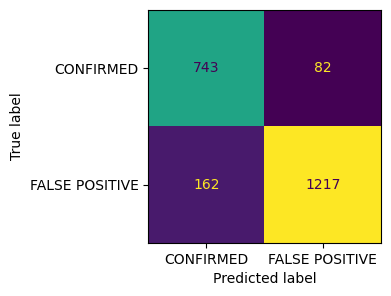

In [37]:
#| echo: false
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_test, svm_rbf_C_optimized.predict(X_test),
      labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
      colorbar=False
   )
   plt.gcf().set_size_inches(4, 4)
   plt.tight_layout();

The RBF-kernel SVM classifier produced a 11.7% false-positive rate and an 9.9% false-negative rate on the test data.  

In this case, Kernel SVM provides ~2% decrease in both false-positive rate and false-negative rate. The additional tuning was very quick (under 1 minute), so this improvement is well worth it if increased computation time the only cost. But the C value also seems very high, indicating the model needed to 

When I impose a C value of 10.4 and re-optimize for gamma, I get a much higher optimal gamma value of 0.156. Cross-validated training error (~89%) is still better than the linear SVM (~87%), and the false-positive and false-negative rates are about 1.5% lower. If we worry about kernel SVM overfitting with the high "optimal" C value, we could lower the C value without much loss in performance.  
	
If a researcher needed a confidence score to accompany the predictions, I'd recommend using logistic regression since it can provide a probability estimate (that gets thresholded by default to yield the class prediction). The threshold could also be easily shifted to account for stronger preference for a false positive or false negative, depending on the circumstances.  

I experimented with several other models including regularized logistic regression (L1 and L2), QDA, several forms of decision tree and classification forest. I chose the random forest as the model to present and advocate for.  


### Random forest
	
I performed a grid search to find the optimal number of features the tree should consier at each split point. These features numbers were tried and scored with cross-validation: 1, 2, 3, 4, 5, 0.33, log (base 2) of the number of total features, and square root of the number of total features. The value of 2 performed best, but upon comparing the performance of each, I opted to use the square root. They all performed almost equally well, and I like that the square root adapts to larger and smaller numbers of features.  

The search was performed with 100 estimators (trees) in the forest.  
I experimented with the number of estimators. One thousand performed marginally better but took significantly longer to compute, so I opted for a value of 200 as a compromise.  

| Accuracy Metric | Value |
|---|---|
| `Training accuracy` | 1.0 |
| `Cross-validated average training accuracy` | 0.9227 |
| `Test accuracy` | 0.9229 |


In [43]:
#| echo: false
rf_model_200 = RandomForestClassifier(random_state=598,
                                      max_features="sqrt",
                                      n_estimators=200)
rf_model_200.fit(X_train, Y_train);

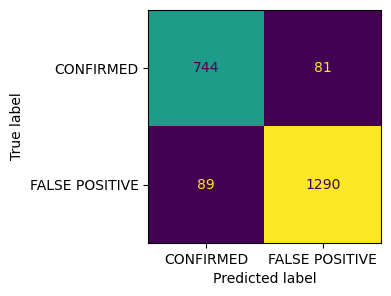

In [44]:
#| echo: false
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_test, rf_model_200.predict(X_test),
      labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
      colorbar=False
   )
   plt.gcf().set_size_inches(4, 4)
   plt.tight_layout();

The random-forest classifier with 200 estimators produced a 6.5% false-positive rate and an 9.8% false-negative rate on the test data.  



With limited resources, I expect false positives to be more expensive than false negatives. Spending telescope time on something that turns out to be a false positive has the opportunity cost of missing out on inspecting something worthwhile. Overall, I propose the random forest algorithm be used to identify candidates for further inspection and analysis, since it has shown overall high accuracy and an especially-low false-positive rate.  
